# Trajectory Plot — Probe vs Foreign Particle

Reads a LAMMPS custom dump file (format: `id type x y`, **wrapped** coordinates,
as produced by the Stage-3 `dump prod` command in the thesis LAMMPS script) and
plots the 2D trajectory of the probe particle (type 1) and the foreign particle
(type 2) side by side.

Because the dump stores wrapped coordinates (not `xu yu`), this notebook
reconstructs the unwrapped trajectory itself by detecting periodic
box-crossings frame-to-frame, using the box bounds read from each frame's
`ITEM: BOX BOUNDS` section.

**Run the cells top to bottom.** Only the Config cell below needs editing.

In [22]:
import numpy as np
import matplotlib.pyplot as plt

## Config — edit these two paths

In [23]:
# Path to the LAMMPS dump file produced by the "dump prod" command
DUMP_FILE = "dump_Ntot2_Np1_Nm1_seed11111"

# Where to save the output figure
OUT_PATH = "trajectory.pdf"

## Parsing functions

In [24]:
def parse_dump(path):
    """
    Parses a LAMMPS custom dump file with columns: id type x y (wrapped).
    Returns:
        frames: list of dicts {id: (type, x, y)}
        box_bounds: list of (xlo, xhi, ylo, yhi), one per frame
    """
    frames = []
    box_bounds = []

    with open(path, "r") as f:
        lines = f.readlines()

    i = 0
    n = len(lines)
    while i < n:
        line = lines[i].strip()
        if line == "ITEM: TIMESTEP":
            i += 2  # skip timestep value
            line = lines[i].strip()
            assert line == "ITEM: NUMBER OF ATOMS"
            i += 1
            natoms = int(lines[i].strip())
            i += 1
            line = lines[i].strip()
            assert line.startswith("ITEM: BOX BOUNDS")
            i += 1
            xlo, xhi = map(float, lines[i].split())
            i += 1
            ylo, yhi = map(float, lines[i].split())
            i += 1
            _ = lines[i]  # zlo zhi, unused (2D system)
            i += 1
            line = lines[i].strip()
            assert line.startswith("ITEM: ATOMS")
            i += 1

            frame = {}
            for _ in range(natoms):
                parts = lines[i].split()
                atom_id = int(parts[0])
                atom_type = int(parts[1])
                x = float(parts[2])
                y = float(parts[3])
                frame[atom_id] = (atom_type, x, y)
                i += 1

            frames.append(frame)
            box_bounds.append((xlo, xhi, ylo, yhi))
        else:
            i += 1

    return frames, box_bounds

In [25]:
def unwrap_trajectory(frames, box_bounds, target_type):
    """
    Extracts and unwraps the trajectory of the single atom matching
    target_type (1 = probe, 2 = foreign), correcting for periodic
    box-crossings frame to frame.

    Returns:
        x_unwrapped, y_unwrapped: numpy arrays (in the dump's native units, e.g. meters)
    """
    xs, ys = [], []
    atom_id_found = None

    for frame, (xlo, xhi, ylo, yhi) in zip(frames, box_bounds):
        # locate the atom of the requested type in this frame
        match = None
        for aid, (atype, x, y) in frame.items():
            if atype == target_type:
                match = (aid, x, y)
                break
        if match is None:
            raise ValueError(f"No atom of type {target_type} found in a frame.")

        aid, x, y = match
        if atom_id_found is None:
            atom_id_found = aid

        xs.append(x)
        ys.append(y)

    xs = np.array(xs)
    ys = np.array(ys)

    # unwrap using per-frame box length (assumes box size is fixed during
    # the production stage, which it is after Stage 2 compression finishes)
    Lx = box_bounds[0][1] - box_bounds[0][0]
    Ly = box_bounds[0][3] - box_bounds[0][2]

    x_unwrapped = xs.copy()
    y_unwrapped = ys.copy()
    offset_x = 0.0
    offset_y = 0.0
    for k in range(1, len(xs)):
        dx = xs[k] - xs[k - 1]
        dy = ys[k] - ys[k - 1]
        if dx > Lx / 2:
            offset_x -= Lx
        elif dx < -Lx / 2:
            offset_x += Lx
        if dy > Ly / 2:
            offset_y -= Ly
        elif dy < -Ly / 2:
            offset_y += Ly
        x_unwrapped[k] = xs[k] + offset_x
        y_unwrapped[k] = ys[k] + offset_y

    return x_unwrapped, y_unwrapped

In [26]:
def plot_trajectories(x_probe, y_probe, x_foreign, y_foreign, out_path):
    """Plots probe and foreign particle trajectories side by side, in micrometers."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    for ax, x, y, label, color in zip(
        axes,
        [x_probe, x_foreign],
        [y_probe, y_foreign],
        ["Probe particle", "Foreign particle"],
        ["#4C72B0", "#DD8452"],
    ):
        x_um = x * 1e6
        y_um = y * 1e6

        ax.plot(x_um, y_um, lw=0.6, color=color, alpha=0.8, label="Trajectory")
        ax.scatter(x_um[0], y_um[0], marker="^", s=120, color="red",
                   edgecolor="black", zorder=5, label="Starting position")
        ax.scatter(x_um[-1], y_um[-1], marker="x", s=120, color="darkred",
                   linewidths=2.5, zorder=5, label="End")

        ax.set_xlabel("x-position (\u00b5m)")
        ax.set_ylabel("y-position (\u00b5m)")
        ax.set_title(label)
        ax.set_aspect("equal", adjustable="datalim")
        ax.legend(loc="upper right", fontsize=8)
        ax.grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig(out_path, dpi=200, bbox_inches='tight')
    print(f"Saved trajectory figure to {out_path}")
    plt.show()

## Run

In [27]:
frames, box_bounds = parse_dump(DUMP_FILE)
print(f"Parsed {len(frames)} frames.")

Parsed 100001 frames.


In [28]:
x_probe, y_probe = unwrap_trajectory(frames, box_bounds, target_type=1)
x_foreign, y_foreign = unwrap_trajectory(frames, box_bounds, target_type=2)

Saved trajectory figure to trajectory.pdf


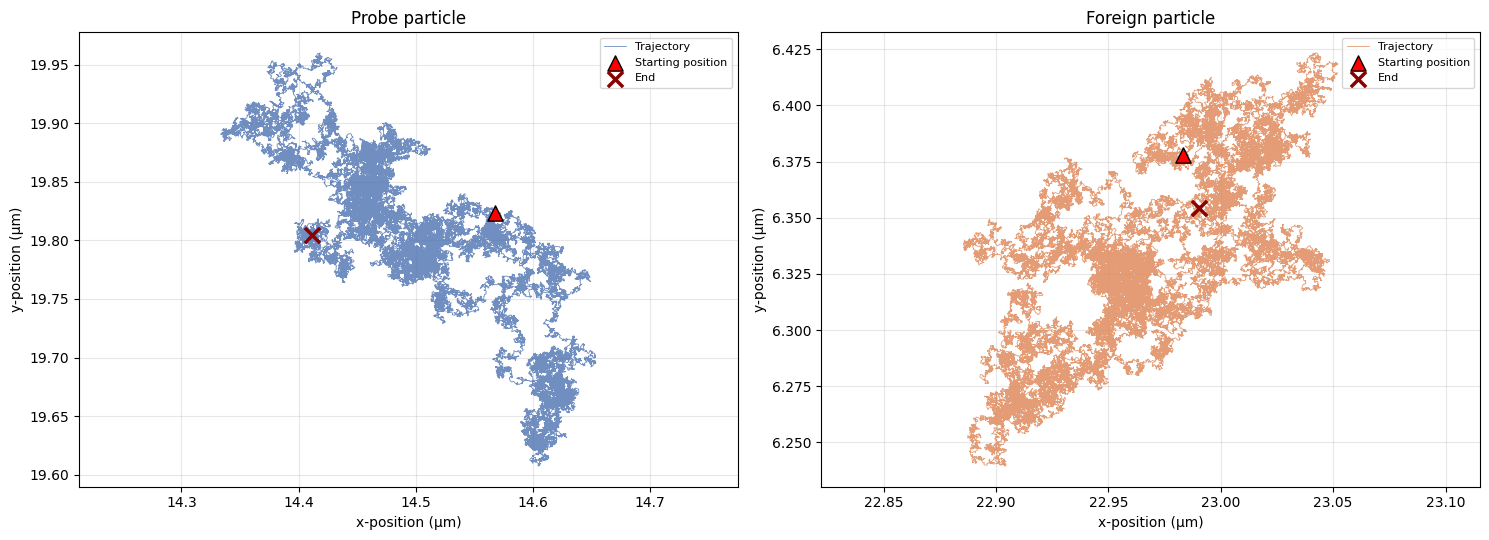

In [29]:
plot_trajectories(x_probe, y_probe, x_foreign, y_foreign, OUT_PATH)